In [1]:
import os
import re
import numpy as np
import pandas as pd
from scipy.stats import kurtosis
from sklearn.covariance import LedoitWolf
from Functions.Graphs import *
from Functions.Utils import *
import seaborn as sns


# Fault-signature DSI (Z) — XJTU-SY bearings

For each bearing folder `BearingX_Y` and each vibration direction (`hor`, `ver`):

1. Operating condition from the folder name (X = 1: 35 Hz / 12 kN, 2: 37.5 Hz / 11 kN, 3: 40 Hz / 10 kN) → characteristic fault frequencies.
2. **Stage layer**: Mahalanobis distance to the healthy baseline + EWMA, and FPT (3σ, consecutive trigger).
3. Demodulation band selection (kurtogram-like spectral kurtosis) on the degraded records.
4. **Fault signature**: envelope-spectrum prominence at BPFO / BPFI / BSF / FTF harmonics and sidebands.
5. **Z**: fault signature z-scored with the healthy baseline ("how many baseline sigmas above normal"), saved at `Dataset\DSIh\BearingX_Y.csv` (horizontal) and `Dataset\DSIv\BearingX_Y.csv` (vertical).

In [2]:
fs = 25600            # XJTU-SY sampling rate [Hz]

# LDK UEH204 geometry (Wang et al., IEEE Trans. Reliab., 2020)
n_balls, d_ball, D_pitch, alpha = 8, 7.92, 34.55, 0.0

CONDITIONS = {1: (35.0, 12), 2: (37.5, 11), 3: (40.0, 10)}   # X: (shaft frequency fr [Hz], radial load [kN])

DatasetPath = r'C:\Users\Usuario\Desktop\Python\Batteries_Prognostics\Dataset'
OUT_DIRS = {'hor': os.path.join(DatasetPath, 'DSIh'), 'ver': os.path.join(DatasetPath, 'DSIv')}

def bearing_condition(bearing_path):
    '''Operating condition from the folder name BearingX_Y -> (name, fr, load).'''
    name = os.path.basename(os.path.normpath(bearing_path))
    m = re.fullmatch(r'Bearing(\d)_(\d+)', name)
    if m is None or int(m.group(1)) not in CONDITIONS:
        raise ValueError(f'Folder name must be BearingX_Y with X in {list(CONDITIONS)}: {name}')
    fr, load = CONDITIONS[int(m.group(1))]
    return name, fr, load

def load_bearing(bearing_path):
    '''All records (1.csv, 2.csv, ...) of a bearing -> {'hor': (records, samples), 'ver': (records, samples)}.'''
    files = sorted((f for f in os.listdir(bearing_path) if f.endswith('.csv')), key=lambda x: int(x.split('.')[0]))
    first = pd.read_csv(os.path.join(bearing_path, files[0]), usecols=['hor', 'ver'])
    data = np.empty((len(files), len(first), 2), dtype=np.float32)
    for k, f in enumerate(files):
        data[k] = pd.read_csv(os.path.join(bearing_path, f), usecols=['hor', 'ver'])[['hor', 'ver']].values
    return {'hor': data[:, :, 0], 'ver': data[:, :, 1]}

## 1. Characteristic fault frequencies

Only the shaft frequency `fr` changes with the operating condition; the fault orders depend on the bearing geometry.

| Fault | Formula |
|---|---|
| Outer race (BPFO) | (n/2)·fr·(1 − d/D·cosα) |
| Inner race (BPFI) | (n/2)·fr·(1 + d/D·cosα) |
| Ball spin (BSF) | (D/2d)·fr·(1 − (d/D·cosα)²) |
| Cage (FTF) | (1/2)·fr·(1 − d/D·cosα) |

In [3]:
def fault_orders(n, d, D, alpha=0.0):
    '''Characteristic fault frequencies as multiples (orders) of the shaft frequency.'''
    r = d / D * np.cos(np.deg2rad(alpha))
    return {'BPFO': n / 2 * (1 - r),
            'BPFI': n / 2 * (1 + r),
            'BSF': D / (2 * d) * (1 - r**2),
            'FTF': 0.5 * (1 - r)}

ORDERS = fault_orders(n_balls, d_ball, D_pitch, alpha)
pd.DataFrame({f'{fr} Hz': {k: o * fr for k, o in ORDERS.items()} for fr, _ in CONDITIONS.values()}).round(2)

,35.0 Hz,37.5 Hz,40.0 Hz
BPFO,107.91,115.62,123.32
BPFI,172.09,184.38,196.68
BSF,72.33,77.50,82.66
FTF,13.49,14.45,15.42


## 2. Stage layer: DSI and FPT

DSI = Mahalanobis distance (Ledoit-Wolf covariance) of a feature vector [log RMS, log kurtosis, log envelope-band energies] to the healthy baseline (first `n_base` records), in baseline-σ units and EWMA-smoothed. FPT = first of 3 consecutive records with DSI > 3σ. The FPT defines the degraded records used to select the demodulation band.

In [4]:
def envelope(x, band=None, fs=fs):
    '''Envelope via analytic signal; the band-pass is done in the frequency domain.'''
    N = len(x)
    S = np.fft.fft(x - x.mean())
    f = np.fft.fftfreq(N, 1 / fs)
    H = np.zeros(N)
    H[f > 0] = 2.0
    if band is not None:
        H[(f < band[0]) | (f > band[1])] = 0.0
    return np.abs(np.fft.ifft(S * H))

def envelope_spectrum(x, band=None, fs=fs):
    '''Amplitude spectrum of the envelope.'''
    env = envelope(x, band, fs)
    env = env - env.mean()
    E = np.abs(np.fft.rfft(env * np.hanning(len(env)))) * 2 / len(env)
    return np.fft.rfftfreq(len(env), 1 / fs), E

def stage_features(x, n_bands=16, fmax=1000):
    '''log RMS, log kurtosis and log band energies of the envelope spectrum (0-fmax Hz).'''
    f, E = envelope_spectrum(x)
    edges = np.linspace(0, fmax, n_bands + 1)
    bands = [np.sum(E[(f >= a) & (f < b)]**2) for a, b in zip(edges[:-1], edges[1:])]
    rms = np.sqrt(np.mean(x**2))
    return np.r_[np.log10(rms), np.log10(kurtosis(x, fisher=False)), np.log10(np.array(bands) + 1e-12)]

def dsi_md(F, n_base=15, lam=0.3):
    '''Mahalanobis distance to the healthy baseline, in baseline-sigma units, EWMA-smoothed (causal).'''
    lw = LedoitWolf().fit(F[:n_base])
    md = np.sqrt(lw.mahalanobis(F))
    md = (md - md[:n_base].mean()) / md[:n_base].std()
    ewma = np.zeros_like(md)
    for i in range(len(md)):
        ewma[i] = lam * md[i] + (1 - lam) * (ewma[i - 1] if i else md[i])
    return md, ewma

def detect_fpt(dsi, thr=3.0, n_consec=3, start=0):
    '''First record of n_consec consecutive values above thr (avoids triggers by random noise).'''
    above = dsi > thr
    for k in range(start, len(dsi) - n_consec + 1):
        if above[k:k + n_consec].all():
            return k
    return None

## 3. Demodulation band (kurtogram-like)

Fault impacts excite a structural resonance; demodulating around it reveals the fault frequencies in the envelope spectrum. The band is chosen on a dyadic grid by maximizing the spectral kurtosis of the squared envelope over the degraded records (Antoni, 2007). Bands above 0.9·Nyquist are excluded (anti-aliasing region).

In [5]:
def band_grid(fr, fs=fs, levels=(1, 2, 3, 4, 5, 6), fmin=200, fmax_ratio=0.9):
    '''Dyadic band grid (1/2^level of the Nyquist band), avoiding the anti-aliasing region.'''
    grid = []
    for lv in levels:
        bw = fs / 2 / 2**lv
        for i in range(2**lv):
            lo, hi = max(i * bw, fmin), (i + 1) * bw
            if hi - lo > 4 * max(ORDERS.values()) * fr and hi <= fmax_ratio * fs / 2:
                grid.append((lo, hi))
    return grid

def select_band(Xd, grid):
    '''Kurtogram criterion: band maximizing the spectral kurtosis (of the squared envelope) over degraded records.'''
    def sk(x, b):
        e2 = envelope(x, b)**2
        return np.mean(e2**2) / np.mean(e2)**2 - 2
    score = np.array([np.mean([sk(x, b) for x in Xd]) for b in grid])
    return grid[int(np.argmax(score))], score

## 4. Fault signature vector

For each characteristic order (BPFO, BPFI, BSF, FTF) and its harmonics 1–3×, plus the BPFI ±fr and 2·BSF ±FTF sidebands: the peak within ±3 % (slip) of the envelope spectrum relative to its local median (noise floor), in log10. Each feature is then z-scored with the healthy baseline (first `n_base` records) → `Z`.

In [6]:
def peak_ratio(f, E, fc, tol=0.025, floor_win=0.2):
    '''Peak within ±tol of fc relative to the local median (noise floor) of the envelope spectrum.'''
    win = (f > fc * (1 - tol)) & (f < fc * (1 + tol))
    if not win.any():                       # window narrower than one bin (e.g. FTF): nearest bin
        win = np.abs(f - fc) == np.abs(f - fc).min()
    ref = (f > fc * (1 - floor_win)) & (f < fc * (1 + floor_win))
    return E[win].max() / (np.median(E[ref]) + 1e-12)

def fault_signature(x, band, fr, n_harm=3):
    f, E = envelope_spectrum(x, band)
    feats = {}
    for name, o in ORDERS.items():
        for h in range(1, n_harm + 1):
            feats[f'{name}_{h}x'] = np.log10(peak_ratio(f, E, h * o * fr))
    for s in (-1, 1):   # inner race: shaft-rate sidebands (load-zone modulation)
        feats[f'BPFI_sb{s:+d}'] = np.log10(peak_ratio(f, E, ORDERS['BPFI'] * fr + s * fr))
    for s in (-1, 1):   # rolling element: cage-rate sidebands
        feats[f'BSF_sb{s:+d}'] = np.log10(peak_ratio(f, E, 2 * ORDERS['BSF'] * fr + s * ORDERS['FTF'] * fr))
    feats['fr_1x'] = np.log10(peak_ratio(f, E, fr))
    return feats

## 5. Z for every bearing and direction

`compute_Z(bearing_path)` identifies the operating condition from the folder name, then, for `hor` and `ver`, runs stage layer → FPT → band → fault signature → Z and saves `Dataset\DSIh\BearingX_Y.csv` and `Dataset\DSIv\BearingX_Y.csv`.

In [7]:
def compute_Z_direction(X, fr, n_base=15, max_band_records=50):
    '''Stage layer (DSI, FPT) -> demodulation band -> fault signature -> z-score w.r.t. the healthy baseline.'''
    t = np.arange(1, len(X) + 1)
    F_stage = np.array([stage_features(x) for x in X])
    _, dsi = dsi_md(F_stage, n_base=n_base)
    fpt = detect_fpt(dsi, start=n_base)
    k0 = fpt if fpt is not None else int(0.8 * len(X))       # no onset detected: last 20 % of life
    # band selection on (at most) max_band_records evenly spaced degraded records
    idx = np.unique(np.linspace(k0, len(X) - 1, min(max_band_records, len(X) - k0)).astype(int))
    band, _ = select_band(X[idx], band_grid(fr))
    SIG = pd.DataFrame([fault_signature(x, band, fr) for x in X], index=t)
    # z-score relative to the healthy baseline: "how many baseline sigmas above normal"
    Z = (SIG - SIG.iloc[:n_base].mean()) / (SIG.iloc[:n_base].std() + 1e-6)
    Z.index.name = 't'
    return Z, fpt, band

def compute_Z(bearing_path, out_dirs=OUT_DIRS, n_base=15):
    '''Z for the horizontal and vertical vibration of a bearing, saved as <out_dirs[direction]>\\BearingX_Y.csv.'''
    name, fr, load = bearing_condition(bearing_path)
    freqs = {k: round(float(o * fr), 2) for k, o in ORDERS.items()}
    print(f'{name}: fr = {fr} Hz, {load} kN -> {freqs} Hz')

    results = {}
    for direction, X in load_bearing(bearing_path).items():
        Z, fpt, band = compute_Z_direction(X, fr, n_base)
        os.makedirs(out_dirs[direction], exist_ok=True)
        Z.to_csv(os.path.join(out_dirs[direction], f'{name}.csv'))
        results[direction] = Z
        fpt_t = fpt + 1 if fpt is not None else None
        print(f'  {direction}: {len(Z)} records, FPT t = {fpt_t}, band {band[0]:.0f}-{band[1]:.0f} Hz')
    return results

In [8]:
print(xx)
XJTUPath = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets"

for name in sorted(os.listdir(XJTUPath)):
    if name.startswith('Bearing1'):
        compute_Z(os.path.join(XJTUPath, name))

NameError: name 'xx' is not defined

In [ ]:
w = 10
a = 0.25
q = 1
brng = 'Bearing1_2.csv'
path = f'Dataset\DSIh\{brng}'
H = (pd.read_csv(path).iloc[:,1:-1])
H = moving_average_df(H,w)
H = exponential_moving_average_df(H,a)**q

path = f'Dataset\DSIv\{brng}'
V = (pd.read_csv(path).iloc[:,1:-1])
V = moving_average_df(V,w)
V = exponential_moving_average_df(V,a)**q

R = (V*H)
#R = np.sqrt((V**2)+(H**2))

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(H.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(V.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(R.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()

# New suggestion

## Harmonic-consistent correction of the fault frequencies (κ)

In damaged bearings the fault lines sit slightly away from the kinematic value. Two effects add up, and both are proportional (the same percentage for every harmonic):

1. **Shaft speed**: the real speed is ~1–2.5 % below the nominal one (motor slip under load). It is estimated per bearing as ρ·fr, with ρ ∈ [0.97, 1.03] (restricted to ±1 bin around the 1× shaft line, so that another comb cannot pull it away, as the BPFO comb of Bearing3_5 did) maximizing the prominence of the shaft harmonics m·fr (m = 1..10) in the **raw** spectrum of the healthy baseline records (first `n_base`), jointly for `hor` and `ver`. If ρ falls on the edge of the search range or < 5 harmonics are clear, ρ = 1.
2. **Fault order**: for each fault type, κ ∈ [0.95, 1.05] maximizes the log prominence of the harmonics κ·h·order·ρ·fr (h = 1..3; FTF: h = 1..6), summed over the **last (up to 20) contiguous blocks of 15 records after the FPT** (mean envelope spectrum of each block, shaft harmonics masked, `hor` and `ver` jointly). A real line keeps the same κ from block to block; noise does not. A block is *clear* at κ if ≥ 2 harmonics exceed 2× the noise floor or the 1× exceeds 4×. κ is accepted if ≥ 2 blocks are clear.

Features of a fault type with an accepted κ use a ±1 % window around the corrected frequencies; the other fault types keep the nominal order and the fixed ±2.5 % window (never worse than the fixed method). `BSF_3x` is excluded: 3·BSF and 2·BPFO are 0.5 % apart and measure the same peak. Speed, band and κ use the whole record (offline, like the band selection).

**Demodulation band**: the fault features and κ use a fixed wide low band, `FEATURE_BAND` = 200–3200 Hz (on the 15 XJTU-SY bearings the fault lines are much clearer there than in the max-kurtosis band, which tracks impulsiveness). The FTF features are also measured in the max-kurtosis band, with a κ estimated in that band (`FTFsk_*`): the weak cage signature of Bearing1_4 is visible only there.

**FTF** features: harmonics 1x–6x and the shaft-rate modulation fr ± FTF (`FTF_sb±1`). BPFO = 8·FTF (8 balls): an outer-race line is also the 8th cage harmonic.

**Baseline**: Z is relative to the bearing's own first `n_base` records, which assumes they are healthy. Bearing3_5 (BPFO ×10 above the floor from minute 1) and Bearing3_2 (BPFI ×10) are already faulty there, so two baseline-free indicators are saved as well:
- **P** (`Dataset\DSIhP`, `Dataset\DSIvP`): the log10 prominence itself (peak / local floor). A pure-noise window gives ~0.2–0.4 (×1.5–2.5); > 0.7 (×5) means a line is present.
- **Pooled Z** (`compute_Z_pooled` → `Dataset\DSIhPool`, `Dataset\DSIvPool`): z relative to the first `n_base` records of the *other* bearings of the same condition (leave-one-out, median and 1.4826·MAD, robust to one faulty baseline among them). Run it after `compute_Z_k` for all bearings.

Z is saved at `Dataset\DSIhK\BearingX_Y.csv` and `Dataset\DSIhV\BearingX_Y.csv` (29 columns; the fixed-window `DSIh` / `DSIv` files are kept).

In [9]:
OUT_DIRS_K = {'hor': os.path.join(DatasetPath, 'DSIhK'), 'ver': os.path.join(DatasetPath, 'DSIhV')}         # z, own baseline
OUT_DIRS_P = {'hor': os.path.join(DatasetPath, 'DSIhP'), 'ver': os.path.join(DatasetPath, 'DSIvP')}         # log10 prominence
OUT_DIRS_POOL = {'hor': os.path.join(DatasetPath, 'DSIhPool'), 'ver': os.path.join(DatasetPath, 'DSIvPool')}  # z, pooled baseline
FEATURE_BAND = (200.0, 3200.0)   # demodulation band of the fault features and of kappa (the fault lines are much clearer
                                 # here than in the max-kurtosis band, which tracks impulsiveness rather than fault lines)
N_HARM = {'BPFO': 3, 'BPFI': 3, 'BSF': 3, 'FTF': 6}   # cage: 1x is 1 bin (~5 %) wide, the 4x-6x harmonics are the clearest

def peak_ratio_k(f, E, fc, tol=0.01, floor_win=0.2):
    '''Peak within ±tol of fc (at least ±1 frequency bin) relative to the local median (noise floor).'''
    df = f[1] - f[0]
    win = np.abs(f - fc) <= max(tol * fc, df)
    ref = np.abs(f - fc) <= floor_win * fc
    return E[win].max() / (np.median(E[ref]) + 1e-12)

def prominence_curve(f, E, fcs, tol=0.005, floor_win=0.2):
    '''peak_ratio_k for an array of centre frequencies fcs, evaluated only on the spectrum region around them.'''
    sl = (f >= fcs.min() * (1 - floor_win) - 2 * (f[1] - f[0])) & (f <= fcs.max() * (1 + floor_win) + 2 * (f[1] - f[0]))
    fs_, Es_ = f[sl], E[sl]
    return np.array([peak_ratio_k(fs_, Es_, fc, tol, floor_win) for fc in fcs])

def raw_spectrum(x, fs=fs):
    x = x - x.mean()
    return np.fft.rfftfreq(len(x), 1 / fs), np.abs(np.fft.rfft(x * np.hanning(len(x))))

def onset_and_band(X, fr, n_base=15, max_band_records=50):
    '''Stage layer (DSI, FPT) and demodulation band, as in compute_Z_direction.'''
    F_stage = np.array([stage_features(x) for x in X])
    _, dsi = dsi_md(F_stage, n_base=n_base)
    fpt = detect_fpt(dsi, start=n_base)
    k0 = fpt if fpt is not None else int(0.8 * len(X))       # no onset detected: last 20 % of life
    idx = np.unique(np.linspace(k0, len(X) - 1, min(max_band_records, len(X) - k0)).astype(int))
    band, _ = select_band(X[idx], band_grid(fr))
    return fpt, band

def estimate_speed_comb(Xb, fr, rhos=np.arange(0.97, 1.0301, 0.0005), n=10, tol=0.002, min_prom=2.0, min_harm=5):
    '''Real shaft frequency rho*fr from the shaft harmonics m*fr of the raw spectrum of the healthy records
    Xb = {'hor': ..., 'ver': ...} (joint score of both directions). rho = 1 if not found or on the grid edge.'''
    f = raw_spectrum(Xb['hor'][0])[0]
    score, P = 0, []
    for X in Xb.values():
        E = np.mean([raw_spectrum(x)[1] for x in X], axis=0)
        P.append(np.array([prominence_curve(f, E, rhos * m * fr, tol) for m in range(1, n + 1)]).T)
        score = score + np.log10(P[-1]).sum(axis=1)
    i = int(np.argmax(score))
    ok = (np.sqrt(P[0][i] * P[1][i]) > min_prom).sum() >= min_harm and 0 < i < len(rhos) - 1
    return rhos[i] if ok else 1.0

def estimate_speed(Xb, fr, rhos=np.arange(0.97, 1.0301, 0.0005), n=10, tol=0.002, min_prom=2.0, min_harm=5, win=0.06):
    '''estimate_speed_comb restricted to +-1 bin around the strongest raw line within +-win of fr (the 1x shaft line),
    so that another comb cannot pull the estimate away (Bearing3_5: 1x at 39.84 Hz, but a strong BPFO comb at
    124.2 Hz ~ 3 x 41.4 Hz gave 41.18 Hz with the free search). If the comb fails, the 1x line itself.'''
    f = raw_spectrum(Xb['hor'][0])[0]
    df = f[1] - f[0]
    E = sum(np.mean([raw_spectrum(x)[1] for x in X], axis=0) for X in Xb.values())
    near = np.where(np.abs(f - fr) <= win * fr)[0]
    f1 = f[near[np.argmax(E[near])]]
    sub = rhos[np.abs(rhos * fr - f1) <= df]
    rho = estimate_speed_comb(Xb, fr, sub, n, tol, min_prom, min_harm) if len(sub) >= 3 else 1.0
    return rho if rho != 1.0 else (f1 / fr if abs(f1 / fr - 1) < 0.03 else 1.0)

def mask_lines(f, E, lines, tol=0.005):
    '''Bins within ±tol (at least ±1 bin) of each line replaced by the spectrum median.'''
    E = E.copy()
    df, med = f[1] - f[0], np.median(E)
    for fl in lines:
        E[np.abs(f - fl) <= max(tol * fl, df)] = med
    return E

def mask_shaft_harmonics(f, E, fr, n=16, tol=0.005):
    '''Shaft harmonics m*fr masked, so that the fault features (and kappa) do not lock on them.'''
    return mask_lines(f, E, [m * fr for m in range(1, n + 1)], tol)

def fault_lines(name, o, fr, n_harm=None, n_sb=1):
    '''Lines of the fault family `name` (o: fault orders): harmonics h*o*fr and their shaft-rate sidebands
    (±1..n_sb * fr); for BSF also 2*BSF ± FTF. n_harm: N_HARM[name] by default.'''
    n_harm = n_harm or N_HARM[name]
    lines = [h * o[name] * fr + s * fr for h in range(1, n_harm + 1) for s in range(-n_sb, n_sb + 1)]
    if name == 'BSF':
        lines += [2 * o['BSF'] * fr + s * o['FTF'] * fr for s in (-1, 1)]
    return lines

def corrected_orders(kappa):
    return {k: v * (kappa[k] or 1.0) for k, v in ORDERS.items()}

def kappa_blocks(n_records, k0, block=15, max_blocks=20):
    '''Start indices of the last (at most max_blocks) contiguous blocks of `block` records between k0 and the end of life.'''
    starts = np.arange(n_records - block, k0 - 1, -block)[:max_blocks][::-1]
    return starts if len(starts) else np.array([max(0, n_records - block)])

def estimate_kappa(D, bands, fr, k0, kappas=np.arange(0.95, 1.0501, 0.001), tol=0.005,
                   block=15, max_blocks=20, min_prom=2.0, strong_prom=4.0, min_blocks=2):
    '''Harmonic-consistent correction of each fault order, from blocks of `block` records after k0.
    For each block, the mean envelope spectrum (shaft harmonics masked) gives the log prominence of the harmonics
    kappa*h*order*fr, jointly for D = {'hor': ..., 'ver': ...} (each direction in its own band). kappa maximizes the
    score summed over the blocks: a real line keeps the same kappa from block to block, noise does not.
    A block is "clear" at kappa if >= 2 harmonics exceed min_prom x floor or the 1x exceeds strong_prom x floor;
    kappa is accepted if >= min_blocks blocks are clear, otherwise None (nominal order and the fixed window are kept).
    Cross-talk: the fault types are accepted one at a time, strongest first (most clear blocks); the lines of the
    accepted types (fault_lines) are masked before kappa is searched again for the remaining types.
    Returns kappa, score, kappas, n_clear and `order` (accepted types, strongest first).'''
    starts = kappa_blocks(len(next(iter(D.values()))), k0, block, max_blocks)
    spectra = {}
    for d, X in D.items():
        f = envelope_spectrum(X[0], bands[d])[0]
        spectra[d] = (f, [mask_shaft_harmonics(f, np.mean([envelope_spectrum(x, bands[d])[1]
                                                            for x in X[s0:s0 + block]], axis=0), fr) for s0 in starts])

    def search(names, lines):
        L = {k: np.zeros((len(starts), len(kappas), N_HARM[k])) for k in names}   # mean log10 prominence (hor, ver)
        for f, blocks in spectra.values():
            for b, E in enumerate(blocks):
                E = mask_lines(f, E, lines)
                for name in names:
                    for h in range(1, N_HARM[name] + 1):
                        L[name][b, :, h - 1] += np.log10(prominence_curve(f, E, kappas * h * ORDERS[name] * fr, tol)) / len(D)
        res = {}
        for name in names:
            s = L[name].sum(axis=(0, 2))
            i = int(np.argmax(s))
            P = 10 ** L[name][:, i, :]                                          # (blocks, harmonics) at kappa
            n_ok = int((((P > min_prom).sum(axis=1) >= 2) | (P[:, 0] > strong_prom)).sum())
            res[name] = (kappas[i], s, n_ok, n_ok >= min(min_blocks, len(starts)))
        return res

    kappa = {k: None for k in ORDERS}
    score, n_clear, order, lines, remaining = {}, {}, [], [], list(ORDERS)
    while remaining:
        res = search(remaining, lines)
        for k in remaining:
            score[k], n_clear[k] = res[k][1], res[k][2]
        accepted = [k for k in remaining if res[k][3]]
        if not accepted:
            break
        best = max(accepted, key=lambda k: (res[k][2], res[k][1].max()))
        kappa[best] = res[best][0]
        order.append(best)
        remaining.remove(best)
        lines += fault_lines(best, corrected_orders(kappa), fr)
    return kappa, score, kappas, n_clear, order

def fault_signature_k(x, band, fr, kappa, order=(), sk=None, tol=0.01, tol_fixed=0.025, exclude=('BSF_3x',)):
    '''Same features as fault_signature at the kappa-corrected fault frequencies: ±tol window for the fault types
    with an accepted kappa, nominal order and ±tol_fixed window otherwise. Shaft harmonics are masked (except for
    fr_1x), and each fault type is measured with the lines of the stronger accepted types (`order`) masked.
    FTF: harmonics 1x-6x (N_HARM) and the shaft-rate modulation fr ± FTF. sk = (band_sk, kappa_sk, order_sk): the FTF
    features are also measured in the max-kurtosis band, with the kappa estimated in that band (FTFsk_*): a weak cage
    signature (e.g. Bearing1_4) may be visible only there.
    `exclude`: features that cannot be told apart from another one (3*BSF and 2*BPFO are 0.5 % apart).'''
    f, E0 = envelope_spectrum(x, band)
    Es = mask_shaft_harmonics(f, E0, fr)
    o = corrected_orders(kappa)
    w = {k: tol if kappa[k] is not None else tol_fixed for k in ORDERS}
    E = {}
    for name in ORDERS:
        stronger = order[:order.index(name)] if name in order else order
        E[name] = mask_lines(f, Es, [fl for k in stronger for fl in fault_lines(k, o, fr)])
    feats = {}
    for name in ORDERS:
        for h in range(1, N_HARM[name] + 1):
            feats[f'{name}_{h}x'] = np.log10(peak_ratio_k(f, E[name], h * o[name] * fr, w[name]))
    for s in (-1, 1):   # inner race: shaft-rate sidebands (load-zone modulation)
        feats[f'BPFI_sb{s:+d}'] = np.log10(peak_ratio_k(f, E['BPFI'], o['BPFI'] * fr + s * fr, w['BPFI']))
    for s in (-1, 1):   # rolling element: cage-rate sidebands
        feats[f'BSF_sb{s:+d}'] = np.log10(peak_ratio_k(f, E['BSF'], 2 * o['BSF'] * fr + s * o['FTF'] * fr, w['BSF']))
    for s in (-1, 1):   # cage: modulation of the shaft rate (fr ± FTF)
        feats[f'FTF_sb{s:+d}'] = np.log10(peak_ratio_k(f, E['FTF'], fr + s * o['FTF'] * fr, w['FTF']))
    if sk is not None:
        band_sk, kappa_sk, order_sk = sk
        feats.update({'FTFsk' + k[3:]: v for k, v in fault_signature_k(x, band_sk, fr, kappa_sk, order_sk).items()
                      if k.startswith('FTF_')})
    feats['fr_1x'] = np.log10(peak_ratio_k(f, E0, fr, tol_fixed))
    return {k: v for k, v in feats.items() if k not in exclude}

def corrections(D, fr, n_base=15, block=15, max_blocks=20, band=FEATURE_BAND):
    '''FPT and max-kurtosis band (bands_sk) per direction, feature band (bands, `band` for both directions), real
    shaft frequency, kappa per fault type and order of the accepted types, estimated in the feature band (kappa,
    order) and in the max-kurtosis band (kappa_sk, order_sk; used for FTFsk_*).'''
    fpt, bands_sk = {}, {}
    for d, X in D.items():
        fpt[d], bands_sk[d] = onset_and_band(X, fr, n_base)
    bands = {d: band for d in D}
    n = len(D['hor'])
    k0 = min(v if v is not None else int(0.8 * n) for v in fpt.values())    # earliest onset of the two directions
    fr_e = estimate_speed({d: X[:n_base] for d, X in D.items()}, fr) * fr
    kappa, score, kappas, n_clear, order = estimate_kappa(D, bands, fr_e, k0, block=block, max_blocks=max_blocks)
    kappa_sk, _, _, _, order_sk = estimate_kappa(D, bands_sk, fr_e, k0, block=block, max_blocks=max_blocks)
    return fpt, bands, bands_sk, fr_e, kappa, score, kappas, n_clear, order, kappa_sk, order_sk

def compute_Z_k(bearing_path, out_dirs=OUT_DIRS_K, sig_dirs=OUT_DIRS_P, n_base=15, block=15, max_blocks=20,
                band=FEATURE_BAND, ftf_sk=True):
    '''Speed- and kappa-corrected features of the horizontal and vertical vibration, saved as BearingX_Y.csv in
    out_dirs[direction]: Z, z-score w.r.t. the bearing's own first n_base records;
    sig_dirs[direction]: P, log10 prominence (peak / local floor), independent of any baseline (a pure-noise window
    gives ~0.3-0.5, i.e. x2-3; > 0.7 (x5) means a line is present). Useful when the fault already exists in the first
    records (Bearing3_2, Bearing3_5); see also compute_Z_pooled.
    ftf_sk: also the FTF features in the max-kurtosis band (FTFsk_*).'''
    name, fr, load = bearing_condition(bearing_path)
    D = load_bearing(bearing_path)
    fpt, bands, bands_sk, fr_e, kappa, _, _, n_clear, order, kappa_sk, order_sk = corrections(D, fr, n_base, block, max_blocks, band)
    kap = {k: (f'{100 * (v - 1):+.1f}%' if v is not None else '-') + f' ({n_clear[k]} blocks)' for k, v in kappa.items()}
    k_sk = f"{100 * (kappa_sk['FTF'] - 1):+.1f}%" if kappa_sk['FTF'] is not None else '-'
    print(f'{name}: fr = {fr} Hz, {load} kN, real fr = {fr_e:.2f} Hz ({100 * (fr_e / fr - 1):+.2f}%), '
          f'kappa - 1 = {kap}, accepted (strongest first) = {order}; '
          f'max-kurtosis band: FTF kappa - 1 = {k_sk}, accepted = {order_sk}')

    results = {}
    for d, X in D.items():
        SIG = pd.DataFrame([fault_signature_k(x, bands[d], fr_e, kappa, order, (bands_sk[d], kappa_sk, order_sk) if ftf_sk else None) for x in X], index=np.arange(1, len(X) + 1))
        # z-score relative to the healthy baseline: "how many baseline sigmas above normal"
        Z = (SIG - SIG.iloc[:n_base].mean()) / (SIG.iloc[:n_base].std() + 1e-6)
        Z.index.name = SIG.index.name = 't'
        for dirs, df in ((out_dirs, Z), (sig_dirs, SIG)):
            os.makedirs(dirs[d], exist_ok=True)
            df.to_csv(os.path.join(dirs[d], f'{name}.csv'))
        results[d] = Z
        fpt_t = fpt[d] + 1 if fpt[d] is not None else None
        print(f'  {d}: {len(Z)} records, FPT t = {fpt_t}, feature band {bands[d][0]:.0f}-{bands[d][1]:.0f} Hz, '
              f'max-kurtosis band {bands_sk[d][0]:.0f}-{bands_sk[d][1]:.0f} Hz')
    return results

def compute_Z_pooled(sig_dirs=OUT_DIRS_P, out_dirs=OUT_DIRS_POOL, n_base=15):
    '''Z w.r.t. a pooled healthy baseline, for bearings whose own first records are already faulty: for each
    prominence file P in sig_dirs, the baseline is the first n_base records of the OTHER bearings of the same
    condition (leave-one-out), with robust statistics (median, 1.4826 x MAD) so that a faulty baseline among them
    (e.g. Bearing3_2) does not shift it. Run after compute_Z_k for all bearings of a condition.'''
    results = {}
    for d in sig_dirs:
        P = {os.path.splitext(f)[0]: pd.read_csv(os.path.join(sig_dirs[d], f), index_col=0)
             for f in sorted(os.listdir(sig_dirs[d])) if f.endswith('.csv')}
        os.makedirs(out_dirs[d], exist_ok=True)
        for name, S in P.items():
            cond = bearing_condition(name)[1]
            pool = [Q.iloc[:n_base] for o, Q in P.items() if o != name and bearing_condition(o)[1] == cond]
            if not pool:
                print(f'  {d} {name}: no other bearing of the same condition, skipped')
                continue
            pool = pd.concat(pool)[S.columns]
            mu = pool.median()
            sd = 1.4826 * (pool - mu).abs().median()
            Z = (S - mu) / (sd + 1e-6)
            Z.to_csv(os.path.join(out_dirs[d], f'{name}.csv'))
            results[(d, name)] = Z
        print(f'{d}: pooled Z for {len([k for k in results if k[0] == d])} bearings -> {out_dirs[d]}')
    return results


### Fixed window vs κ-corrected window (Bearing2_1 and Bearing3_3)

Left: κ search score of each fault type (peaks of a real fault line up at the same κ for all harmonics). Middle/right: mean z-score of the features of each fault type, with the fixed window and with the κ-corrected window.

In [ ]:
'''XJTUPath = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets"
n_base = 15
cols = dict(BPFO='tab:blue', BPFI='tab:red', BSF='tab:green', FTF='tab:orange')

def group_mean(SIG, n_base=n_base):
    '''Z of SIG, then mean z-score of the features of each fault type (harmonics and sidebands).'''
    Z = (SIG - SIG.iloc[:n_base].mean()) / (SIG.iloc[:n_base].std() + 1e-6)
    return pd.DataFrame({k: Z[[c for c in Z.columns if c.startswith(k)]].mean(axis=1) for k in ORDERS})

for brng in ['Bearing1_1', 'Bearing1_2', 'Bearing2_1', 'Bearing3_3']:
    name, fr, load = bearing_condition(os.path.join(XJTUPath, brng))
    D = load_bearing(os.path.join(XJTUPath, brng))
    fpt, bands, bands_sk, fr_e, kappa, score, kappas, n_clear, order, kappa_sk, order_sk = corrections(D, fr, n_base)
    print(f'{name}: real fr = {fr_e:.2f} Hz ({100 * (fr_e / fr - 1):+.2f}%), kappa =',
          {k: (f'{v:.3f}' if v is not None else 'not accepted') + f' ({n_clear[k]} blocks)' for k, v in kappa.items()},
          'accepted:', order)

    fig, ax = plt.subplots(1, 5, figsize=(22, 3.5))
    for k in ORDERS:
        ax[0].plot(100 * (kappas - 1), score[k], c=cols[k], label=k)
    ax[0].set_xlabel('κ − 1 [%]'); ax[0].set_ylabel('Σ log10 prominence (blocks, harmonics)')
    ax[0].set_title('κ search (blocks after FPT, hor + ver)'); ax[0].legend()
    for j, (d, X) in enumerate(D.items()):
        t = np.arange(1, len(X) + 1)
        G_fix = group_mean(pd.DataFrame([fault_signature(x, bands[d], fr) for x in X], index=t))
        G_k = group_mean(pd.DataFrame([fault_signature_k(x, bands[d], fr_e, kappa, order, (bands_sk[d], kappa_sk, order_sk)) for x in X], index=t))
        for a, G, lab in [(ax[1 + 2 * j], G_fix, f'fixed ±{peak_ratio.__defaults__[0] * 100:.1f} %'),
                          (ax[2 + 2 * j], G_k, 'speed + κ corrected')]:
            for k in ORDERS: a.plot(t, G[k], c=cols[k], label=k)
            a.axhline(3, c='k', ls=':', lw=1); a.set_xlabel('t [min]'); a.set_ylabel('mean z [baseline σ]')
            a.set_title(f'{d}: {lab}')
            if fpt[d] is not None: a.axvline(t[fpt[d]], c='r', alpha=.4)
    fig.suptitle(name); fig.tight_layout(); plt.show()'''

In [10]:
XJTUPath = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets"

for name in sorted(os.listdir(XJTUPath)):
    if not name.startswith('Bearing3'):
    #if name.startswith('Bearing3'):
        compute_Z_k(os.path.join(XJTUPath, name))

Bearing1_1: fr = 35.0 Hz, 12 kN, real fr = 34.16 Hz (-2.40%), kappa - 1 = {'BPFO': '+3.6% (6 blocks)', 'BPFI': '+0.7% (3 blocks)', 'BSF': '+5.0% (2 blocks)', 'FTF': '+4.7% (3 blocks)'}, accepted (strongest first) = ['BPFO', 'BPFI', 'FTF', 'BSF']; max-kurtosis band: FTF kappa - 1 = +4.7%, accepted = ['FTF', 'BPFO']
  hor: 123 records, FPT t = 16, feature band 200-3200 Hz, max-kurtosis band 9600-10400 Hz
  ver: 123 records, FPT t = 18, feature band 200-3200 Hz, max-kurtosis band 9600-10400 Hz
Bearing1_2: fr = 35.0 Hz, 12 kN, real fr = 34.32 Hz (-1.95%), kappa - 1 = {'BPFO': '+1.9% (9 blocks)', 'BPFI': '+4.9% (5 blocks)', 'BSF': '+2.5% (8 blocks)', 'FTF': '- (1 blocks)'}, accepted (strongest first) = ['BPFO', 'BSF', 'BPFI']; max-kurtosis band: FTF kappa - 1 = -, accepted = ['BPFO', 'BSF']
  hor: 161 records, FPT t = 17, feature band 200-3200 Hz, max-kurtosis band 6400-8000 Hz
  ver: 161 records, FPT t = 18, feature band 200-3200 Hz, max-kurtosis band 9600-11200 Hz
Bearing1_3: fr = 35.0 Hz

In [ ]:
# after compute_Z_k for all bearings: z w.r.t. the healthy baseline of the other bearings of the same condition
Z_pool = compute_Z_pooled()

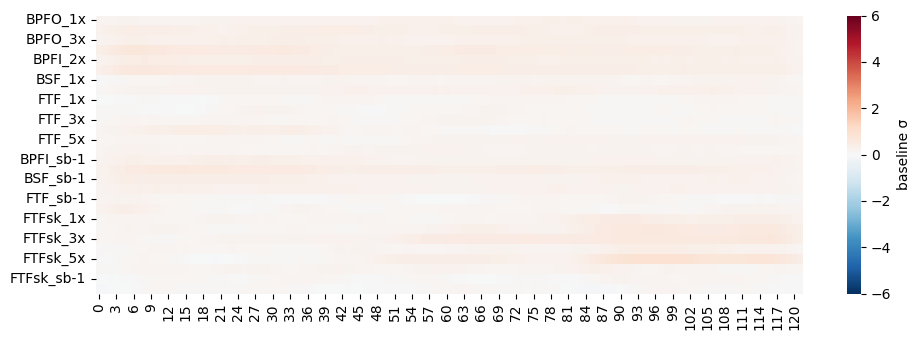

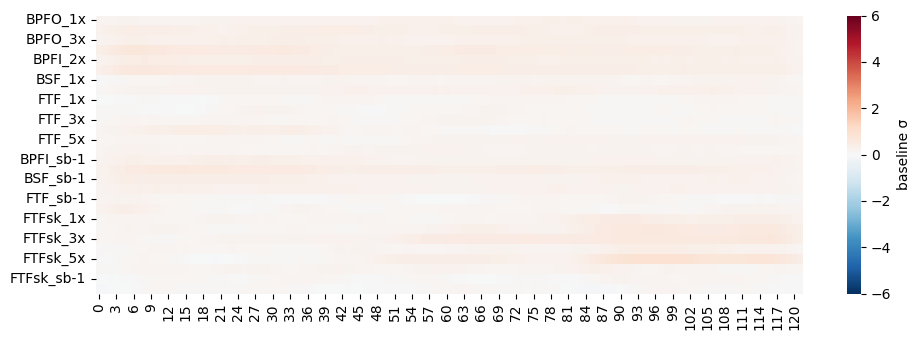

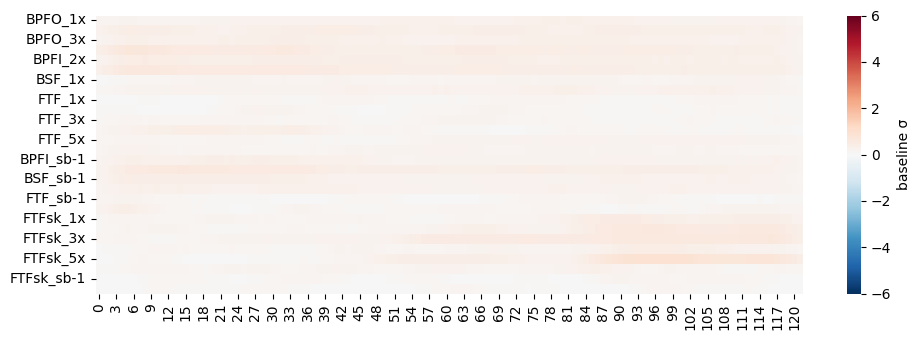

In [16]:
w = 10
a = 0.5
brng = 'Bearing1_4.csv'
path = f'Dataset\DSIhP\{brng}'
H = (pd.read_csv(path).iloc[:,1:-1])
H = exponential_moving_average_df(H,a)
H = moving_average_df(H,w)

path = f'Dataset\DSIhP\{brng}'
V = (pd.read_csv(path).iloc[:,1:-1])
V = exponential_moving_average_df(V,a)
V = moving_average_df(V,w)

R = np.sqrt(H.clip(lower=0) * V.clip(lower=0))
R = (H.clip(lower=0) + V.clip(lower=0))/2

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(H.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(V.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(R.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()